# Эксперименты 4–5: словоформа, лексема и смысл



## 1. Подготовить среду


In [ ]:
%pip -q install "transformers==4.48.3" "accelerate>=1.2.0" "bitsandbytes>=0.45.0" "wordfreq>=3.1.1" pymorphy3 pymorphy3-dicts-ru pandas matplotlib tqdm

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.4/44.4 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.7/9.7 MB 47.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 17.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.8/56.8 MB 15.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.4/8.4 MB 45.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 566.4/566.4 kB 24.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 183.1/183.1 kB 11.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.1/3.1 MB 47.8 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.29.0 requires huggingface-hub

## 2. Настройки

- `N_SPLIT_WORDS`, `N_TYPO_WORDS` — сколько однотокенных слов брать для 4.1а и 4.1б;
- `N_MULTI_WORDS` — сколько многотокенных слов брать для Patchscopes (самая долгая часть; для быстрой пробы поставьте 50);
- `PATCHSCOPES_PROMPT` — промпт для «повторения» слова. В репозитории авторов он английский: `"Next is the same word twice: 1) {word} 2)"`. Для русских слов мы используем его перевод. Можно вернуть английский вариант и сравнить.

In [ ]:
import os
import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
from wordfreq import top_n_list
import pymorphy3
from transformers import AutoTokenizer, AutoModelForCausalLM, BitsAndBytesConfig

SEED = 42
MODEL_NAME = "IlyaGusev/saiga_llama3_8b"
TOP_N_WORDS = 100_000
N_SPLIT_WORDS = 1_000
N_TYPO_WORDS = 1_000
N_MULTI_WORDS = 400
MIN_TOKENS, MAX_TOKENS = 2, 4      # многотокенные слова — как в ноутбуке по разделу 3
BATCH_SIZE = 16
PATCHSCOPES_PROMPT = "Далее одно и то же слово дважды: 1) {word} 2)"
# Вариант из репозитория авторов: "Next is the same word twice: 1) {word} 2)"
USE_4BIT = True
RESULT_DIR = "/content/saiga_section4_results"
os.makedirs(RESULT_DIR, exist_ok=True)

rng = np.random.default_rng(SEED)
torch.manual_seed(SEED)
if not torch.cuda.is_available():
    raise RuntimeError("Нужен GPU: в Colab выберите Runtime → Change runtime type → GPU.")
print("GPU:", torch.cuda.get_device_name(0))

GPU: Tesla T4


## 3. Загрузить модель

Так же, как в ноутбуке по разделу 3: без chat template, в 4-битном режиме для T4. Матрица входных эмбеддингов при 4-битной загрузке не квантуется, поэтому logit lens работает с теми же векторами, что и в полной модели.

In [ ]:
COMPUTE_DTYPE = torch.bfloat16 if torch.cuda.is_bf16_supported() else torch.float16

tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME, use_fast=True)
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token
PAD_ID = tokenizer.pad_token_id
BOS_ID = tokenizer.bos_token_id

load_kwargs = {"device_map": "auto", "torch_dtype": COMPUTE_DTYPE, "low_cpu_mem_usage": True}
if USE_4BIT:
    load_kwargs["quantization_config"] = BitsAndBytesConfig(
        load_in_4bit=True, bnb_4bit_quant_type="nf4",
        bnb_4bit_use_double_quant=True, bnb_4bit_compute_dtype=COMPUTE_DTYPE,
    )
model = AutoModelForCausalLM.from_pretrained(MODEL_NAME, **load_kwargs)
model.eval()

DEVICE = model.get_input_embeddings().weight.device
N_LAYERS = model.config.num_hidden_layers          # 32
N_STATES = N_LAYERS + 1                            # + выход embedding-слоя (слой 0)
print("Слоёв:", N_LAYERS, "| словарь:", len(tokenizer))

/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


tokenizer_config.json: 0.00B [00:00, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/446 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/689 [00:00<?, ?B/s]

...

model-00003-of-00004.safetensors:   0%|          | 0.00/4.92G [00:00<?, ?B/s]

model-00004-of-00004.safetensors:   0%|          | 0.00/1.17G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/4 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/277 [00:00<?, ?B/s]

Слоёв: 32 | словарь: 128256


## 4. Материал: те же русские слова, что в разделе 3

Берём частотный список `wordfreq`, оставляем слова из русских букв длиной от 3 символов и пропускаем через словарную чистку pymorphy3 (без имён собственных и аббревиатур). Затем делим слова по тому, как их режет токенизатор Saiga (с начальным пробелом, как слово внутри текста):

- **однотокенные** слова длиннее 3 букв — материал для 4.1а и 4.1б;
- слова из **2–4 токенов** — материал для 4.2, ровно как в ноутбуке по разделу 3.

In [ ]:
morph = pymorphy3.MorphAnalyzer()
PROPER_OR_ABBR = {"Name", "Surn", "Patr", "Geox", "Orgn", "Trad", "Abbr", "Init"}


def is_common_dictionary_word(word):
    if not morph.word_is_known(word):
        return False
    return not any(g in morph.parse(word)[0].tag for g in PROPER_OR_ABBR)


all_frequency_forms = set()
dictionary_words = []
for raw in tqdm(top_n_list("ru", TOP_N_WORDS), desc="Отбор слов"):
    w = unicodedata.normalize("NFC", raw.strip().lower())
    if not re.fullmatch(r"[а-яё]+", w) or len(w) < 3 or w in all_frequency_forms:
        continue
    all_frequency_forms.add(w)
    if is_common_dictionary_word(w):
        dictionary_words.append(w)

single_token_words, multi_token_words = [], []
seen_seqs = set()
for start in range(0, len(dictionary_words), 2048):
    batch = dictionary_words[start:start + 2048]
    enc = tokenizer([" " + w for w in batch], add_special_tokens=False)["input_ids"]
    for w, ids in zip(batch, enc):
        if tuple(ids) in seen_seqs:
            continue
        seen_seqs.add(tuple(ids))
        if len(ids) == 1 and len(w) > 3:
            single_token_words.append({"word": w, "token_id": ids[0]})
        elif MIN_TOKENS <= len(ids) <= MAX_TOKENS:
            multi_token_words.append({"word": w, "token_ids": list(ids)})

print("Словарных слов:", len(dictionary_words))
print("Однотокенных (длиннее 3 букв):", len(single_token_words))
print("Из 2–4 токенов:", len(multi_token_words))
print("Примеры однотокенных:", ", ".join(x["word"] for x in single_token_words[:15]))

Отбор слов:   0%|          | 0/100000 [00:00<?, ?it/s]

Словарных слов: 83920
Однотокенных (длиннее 3 букв): 1030
Из 2–4 токенов: 76674
Примеры однотокенных: только, если, когда, было, меня, будет, время, года, чтобы, есть, может, после, очень, были, была


## 5. Инструменты: logit lens и Patchscopes

Здесь три функции; только они обращаются к модели.

- `logit_lens_top1(sequences)` — прогоняет каждую последовательность токенов (с BOS в начале) через модель и на **каждом** слое берёт вектор последнего токена. Этот вектор умножается на матрицу входных эмбеддингов; токен с наибольшим произведением и есть «на что похож вектор». Это ровно `ReverseLogitLens` из репозитория.
- `last_token_states(sequences)` — то же, но возвращает сами векторы (нужны для Patchscopes).
- `patchscopes_outputs(vectors, n_new_tokens)` — подставляет каждый вектор в промпт «Далее одно и то же слово дважды: 1) **X** 2)» на место X и даёт модели продолжить текст. Если вектор «содержит» слово, модель допишет его после «2)».

In [ ]:
EMBED = model.get_input_embeddings().weight          # (размер словаря, 4096)


def _batch_inputs(sequences):
    rows = [[BOS_ID] + list(s) for s in sequences]
    max_len = max(len(r) for r in rows)
    input_ids = torch.full((len(rows), max_len), PAD_ID, dtype=torch.long)
    mask = torch.zeros((len(rows), max_len), dtype=torch.long)
    for i, r in enumerate(rows):
        input_ids[i, :len(r)] = torch.tensor(r)
        mask[i, :len(r)] = 1
    last_pos = torch.tensor([len(r) - 1 for r in rows])
    return input_ids.to(DEVICE), mask.to(DEVICE), last_pos.to(DEVICE)


@torch.inference_mode()
def last_token_states(sequences):
    # Векторы последнего токена на всех слоях: тензор (N_STATES, len(sequences), 4096).
    input_ids, mask, last_pos = _batch_inputs(sequences)
    out = model(input_ids=input_ids, attention_mask=mask, output_hidden_states=True, use_cache=False)
    rows = torch.arange(len(sequences), device=DEVICE)
    return torch.stack([h[rows, last_pos] for h in out.hidden_states])


@torch.inference_mode()
def logit_lens_top1(sequences):
    # Для каждого слоя и каждой последовательности — id самого похожего токена (numpy, N_STATES x N).
    result = []
    for start in tqdm(range(0, len(sequences), BATCH_SIZE), desc="logit lens", leave=False):
        states = last_token_states(sequences[start:start + BATCH_SIZE])   # (L, B, H)
        scores = states.to(EMBED.dtype) @ EMBED.T                          # (L, B, словарь)
        result.append(scores.argmax(dim=-1).cpu().numpy())
    return np.concatenate(result, axis=1)


# Промпт Patchscopes: BOS + текст до {word} + место для вектора + текст после {word}.
_prefix, _suffix = PATCHSCOPES_PROMPT.split("{word}")
_prompt_ids = ([BOS_ID] + tokenizer.encode(_prefix, add_special_tokens=False) + [0]
               + tokenizer.encode(_suffix, add_special_tokens=False))
PATCH_POS = 1 + len(tokenizer.encode(_prefix, add_special_tokens=False))
_prompt_embeds = EMBED[torch.tensor(_prompt_ids, device=DEVICE)]


@torch.inference_mode()
def patchscopes_outputs(vectors, n_new_tokens):
    # vectors: (N, 4096). Возвращает N строк, которые модель дописала после промпта.
    embeds = _prompt_embeds.unsqueeze(0).repeat(len(vectors), 1, 1).clone()
    embeds[:, PATCH_POS] = vectors.to(embeds.dtype)
    mask = torch.ones(embeds.shape[:2], dtype=torch.long, device=DEVICE)
    out = model.generate(inputs_embeds=embeds, attention_mask=mask, max_new_tokens=n_new_tokens,
                         do_sample=False, num_beams=1, temperature=None, top_p=None, top_k=None,
                         pad_token_id=PAD_ID)
    return tokenizer.batch_decode(out, skip_special_tokens=True)


# Проверка инструментов на одном слове без разбиения: на ранних слоях logit lens должен
# вернуть само слово, потому что вектор последнего токена — это его собственный эмбеддинг.
_w = single_token_words[0]
_top = logit_lens_top1([[_w["token_id"]]])[:, 0]
print(f"Проверка на слове «{_w['word']}»: слой 0 →", repr(tokenizer.decode([_top[0]])),
      "| слой 16 →", repr(tokenizer.decode([_top[16]])))

logit lens:   0%|          | 0/1 [00:00<?, ?it/s]

Проверка на слове «только»: слой 0 → ' только' | слой 16 → 'Only'


## 6. Эксперимент 4.1а: искусственно разбитые однотокенные слова

Берём слово, которое в словаре модели есть целиком (« стол» — один токен), и режем его на 2–5 случайных частей: « ст» + «ол». Модель никогда не видела это слово в таком виде. Если на каком-то слое вектор последнего куска «ол» становится похож на эмбеддинг целого « стол», значит, модель собрала слово.

**Метрика (как в статье):** доля слов, для которых на данном слое лучший токен по logit lens — исходное слово.

In [ ]:
def split_word(word, rng):
    # Режем слово на k случайных частей (2 <= k <= 5) и токенизируем каждую часть отдельно.
    k = int(rng.integers(2, min(5, len(word)) + 1))
    cuts = sorted(rng.choice(np.arange(1, len(word)), size=k - 1, replace=False).tolist())
    pieces = [word[a:b] for a, b in zip([0] + cuts, cuts + [len(word)])]
    ids = tokenizer.encode(" " + pieces[0], add_special_tokens=False)
    for p in pieces[1:]:
        ids += tokenizer.encode(p, add_special_tokens=False)
    return pieces, ids


pool = [single_token_words[i] for i in rng.permutation(len(single_token_words))]
split_data = []
for item in pool[:N_SPLIT_WORDS]:
    pieces, ids = split_word(item["word"], rng)
    split_data.append({"word": item["word"], "target_id": item["token_id"],
                       "pieces": "|".join(pieces), "input_ids": ids})

split_top = logit_lens_top1([d["input_ids"] for d in split_data])            # (N_STATES, N)
split_hits = split_top == np.array([d["target_id"] for d in split_data])[None, :]

print(f"Слов: {len(split_data)}. Пример разбиения: «{split_data[0]['word']}» → {split_data[0]['pieces']}")
print(f"Пик: {split_hits.mean(1).max():.1%} на слое {split_hits.mean(1).argmax()}; "
      f"хотя бы на одном слое: {split_hits.any(0).mean():.1%}")

logit lens:   0%|          | 0/63 [00:00<?, ?it/s]

Слов: 1000. Пример разбиения: «директор» → д|ир|ектор
Пик: 11.1% на слое 6; хотя бы на одном слое: 25.3%


## 7. Эксперимент 4.1б: опечатки

Те же однотокенные слова, но с одной опечаткой, как в репозитории авторов (`introduce_typo` в `processor.py`): замена буквы, удаление, вставка или перестановка двух соседних букв. Первая буква не трогается. Слово с опечаткой токенизатор режет на несколько кусков уже сам.

Русская деталь: опечатка может случайно дать другое настоящее слово («стол» → «стул»). Такие случаи отбрасываем (проверка по pymorphy3 и частотному списку), иначе модель «узнавала» бы не то слово.

**Метрика:** доля слов, для которых лучший токен по logit lens — **исходное, правильно написанное** слово.

In [ ]:
RU_LETTERS = "абвгдеёжзийклмнопрстуфхцчшщъыьэюя"


def introduce_typo(word, rng):
    kind = rng.choice(["substitution", "deletion", "insertion", "transposition"])
    pos = int(rng.integers(1, len(word)))                  # первую букву не трогаем
    if kind == "substitution":
        return word[:pos] + rng.choice([c for c in RU_LETTERS if c != word[pos]]) + word[pos + 1:]
    if kind == "deletion":
        return word[:pos] + word[pos + 1:]
    if kind == "insertion":
        return word[:pos] + rng.choice(list(RU_LETTERS)) + word[pos:]
    pos = min(pos, len(word) - 2)                          # перестановка соседних букв
    return word[:pos] + word[pos + 1] + word[pos] + word[pos + 2:]


typo_data = []
for item in pool[N_SPLIT_WORDS:] + pool[:N_SPLIT_WORDS]:   # сначала слова, не занятые в 4.1а
    if len(typo_data) >= N_TYPO_WORDS:
        break
    if len(item["word"]) <= 4:                              # как в статье: слова длиннее 4 букв
        continue
    for _ in range(20):
        typo = introduce_typo(item["word"], rng)
        ids = tokenizer.encode(" " + typo, add_special_tokens=False)
        if len(ids) >= 2 and typo not in all_frequency_forms and not morph.word_is_known(typo):
            typo_data.append({"word": item["word"], "target_id": item["token_id"],
                              "typo": typo, "input_ids": ids})
            break

typo_top = logit_lens_top1([d["input_ids"] for d in typo_data])
typo_hits = typo_top == np.array([d["target_id"] for d in typo_data])[None, :]

print(f"Слов: {len(typo_data)}. Пример: «{typo_data[0]['word']}» → «{typo_data[0]['typo']}»")
print(f"Пик: {typo_hits.mean(1).max():.1%} на слое {typo_hits.mean(1).argmax()}; "
      f"хотя бы на одном слое: {typo_hits.any(0).mean():.1%}")

logit lens:   0%|          | 0/47 [00:00<?, ?it/s]

Слов: 745. Пример: «потер» → «потре»
Пик: 2.8% на слое 7; хотя бы на одном слое: 6.3%


## 8. Эксперимент 4.2: многотокенные слова (Patchscopes)

Для слов из 2–4 токенов («осьминога» = 3 куска) целого токена в словаре нет, поэтому logit lens не подходит: сравнивать не с чем. Вместо этого, как в статье, используем Patchscopes:

1. прогоняем слово через модель и берём вектор последнего куска на каждом слое 1–32;
2. в отдельном прогоне подставляем этот **один** вектор в промпт «Далее одно и то же слово дважды: 1) **X** 2)» вместо X;
3. смотрим, что модель напишет после «2)».

Если модель напишет «осьминога», значит, один вектор последнего куска содержит всё слово, хотя на входе модель такой вектор никогда не видела.

**Метрика (как в `identified_in_patchscopes.py`):** ответ модели (без пробелов по краям, в нижнем регистре) начинается с исходного слова.

Это самая долгая часть: на каждое слово 32 генерации (по одной на слой), они идут одним батчем.

In [ ]:
multi_pool = [multi_token_words[i] for i in rng.permutation(len(multi_token_words))[:N_MULTI_WORDS]]
LAYERS_PATCH = list(range(1, N_STATES))                  # слои 1..32, как в репозитории

patch_rows = []
patch_hits = np.zeros((len(LAYERS_PATCH), len(multi_pool)), dtype=bool)
for j, item in enumerate(tqdm(multi_pool, desc="Patchscopes")):
    states = last_token_states([item["token_ids"]])[1:, 0]          # (32, 4096)
    outputs = patchscopes_outputs(states, n_new_tokens=len(item["token_ids"]) + 3)
    for li, (layer, text) in enumerate(zip(LAYERS_PATCH, outputs)):
        answer = text.strip().lower()
        hit = answer.startswith(item["word"])
        patch_hits[li, j] = hit
        patch_rows.append({"word": item["word"], "n_tokens": len(item["token_ids"]),
                           "layer": layer, "output": text, "hit": hit})

patch_df = pd.DataFrame(patch_rows)
print(f"Слов: {len(multi_pool)}. Пик: {patch_hits.mean(1).max():.1%} на слое "
      f"{LAYERS_PATCH[patch_hits.mean(1).argmax()]}; хотя бы на одном слое: {patch_hits.any(0).mean():.1%}")

Patchscopes:   0%|          | 0/400 [00:00<?, ?it/s]

Слов: 400. Пик: 10.5% на слое 7; хотя бы на одном слое: 17.2%


## 9. Результаты

**График слева** (как рис. 3a статьи): доля восстановленных слов по слоям для разбитых и для опечатанных однотокенных слов.
**График в центре** (как рис. 3b): то же для многотокенных слов через Patchscopes.
**График справа** (как рис. 11): накопленная доля — сколько слов восстановлено хотя бы на одном слое к данному.

Ниже — сводная таблица рядом с цифрами из статьи для Llama2-7B (в приложении C статьи есть и кривые для Llama3-8B, на которой основана Saiga) и примеры, на которые полезно посмотреть глазами.

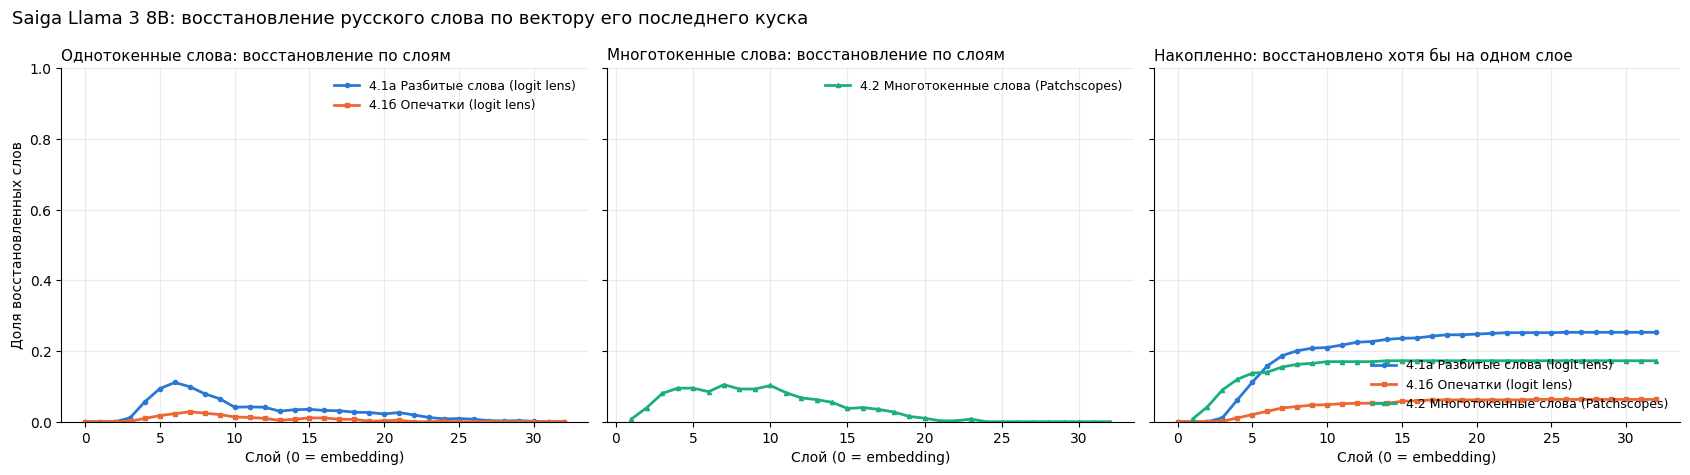

,Эксперимент,Слов,Пиковый слой,Доля на пиковом слое,Хотя бы на одном слое,Ни на одном слое,"Статья, Llama2-7B: пик","Статья, Llama2-7B: хотя бы на одном"
0,4.1а Разбитые слова (logit lens),1000,6,11.1%,25.3%,74.7%,"> 80%, слой ~15",93.2%
1,4.1б Опечатки (logit lens),745,7,2.8%,6.3%,93.7%,"~40%, слой ~15",66%
2,4.2 Многотокенные слова (Patchscopes),400,7,10.5%,17.2%,82.8%,"64%, слои 5–7",77.4%


Коротко:
• 4.1а Разбитые слова (logit lens): чаще всего слово восстанавливается на слое 6 (11.1%); хотя бы на одном слое — 25.3% слов.
• 4.1б Опечатки (logit lens): чаще всего слово восстанавливается на слое 7 (2.8%); хотя бы на одном слое — 6.3% слов.
• 4.2 Многотокенные слова (Patchscopes): чаще всего слово восстанавливается на слое 7 (10.5%); хотя бы на одном слое — 17.2% слов.


In [ ]:
def per_layer(hits):
    return hits.mean(axis=1)


def cumulative(hits):
    return np.logical_or.accumulate(hits, axis=0).mean(axis=1)


layers_all = np.arange(N_STATES)
curves = [
    ("4.1а Разбитые слова (logit lens)", layers_all, split_hits, "#2a78d6", "o"),
    ("4.1б Опечатки (logit lens)", layers_all, typo_hits, "#eb6834", "s"),
    ("4.2 Многотокенные слова (Patchscopes)", np.array(LAYERS_PATCH), patch_hits, "#1baf7a", "^"),
]

plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "font.size": 10})
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for name, xs, hits, color, mk in curves:
    ax = axes[0] if name.startswith("4.1") else axes[1]
    ax.plot(xs, per_layer(hits), color=color, lw=2, marker=mk, ms=3, label=name)
    axes[2].plot(xs, cumulative(hits), color=color, lw=2, marker=mk, ms=3, label=name)
titles = ["Однотокенные слова: восстановление по слоям",
          "Многотокенные слова: восстановление по слоям",
          "Накопленно: восстановлено хотя бы на одном слое"]
for ax, title, loc in zip(axes, titles, ["upper right", "upper right", "lower right"]):
    ax.set_title(title, loc="left", fontsize=11)
    ax.set_xlabel("Слой (0 = embedding)")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, fontsize=9, loc=loc)
axes[0].set_ylabel("Доля восстановленных слов")
axes[0].set_ylim(0, 1)
fig.suptitle("Saiga Llama 3 8B: восстановление русского слова по вектору его последнего куска",
             x=0.01, ha="left", fontsize=13)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "section4_retrieval_by_layer.png"), dpi=180, bbox_inches="tight")
plt.show()

PAPER_LLAMA2 = {  # цифры из текста статьи (раздел 4 и приложение C)
    "4.1а Разбитые слова (logit lens)": ("> 80%, слой ~15", "93.2%"),
    "4.1б Опечатки (logit lens)": ("~40%, слой ~15", "66%"),
    "4.2 Многотокенные слова (Patchscopes)": ("64%, слои 5–7", "77.4%"),
}
summary = []
for name, xs, hits, _, _ in curves:
    rate = per_layer(hits)
    summary.append({
        "Эксперимент": name,
        "Слов": hits.shape[1],
        "Пиковый слой": int(xs[rate.argmax()]),
        "Доля на пиковом слое": f"{rate.max():.1%}",
        "Хотя бы на одном слое": f"{hits.any(axis=0).mean():.1%}",
        "Ни на одном слое": f"{1 - hits.any(axis=0).mean():.1%}",
        "Статья, Llama2-7B: пик": PAPER_LLAMA2[name][0],
        "Статья, Llama2-7B: хотя бы на одном": PAPER_LLAMA2[name][1],
    })
summary_df = pd.DataFrame(summary)
display(summary_df)

print("Коротко:")
for row in summary:
    print(f"• {row['Эксперимент']}: чаще всего слово восстанавливается на слое {row['Пиковый слой']} "
          f"({row['Доля на пиковом слое']}); хотя бы на одном слое — {row['Хотя бы на одном слое']} слов.")

In [ ]:
SHOW_LAYERS = [0, 4, 8, 12, 16, 20, 24, 28, 32]


def lens_examples(data, top, label_col, n=8):
    rows = []
    for j in range(min(n, len(data))):
        row = {"слово": data[j]["word"], "на входе": data[j][label_col]}
        for L in SHOW_LAYERS:
            row[f"слой {L}"] = tokenizer.decode([int(top[L, j])]).strip()
        rows.append(row)
    return pd.DataFrame(rows)


print("4.1а: на какой токен похож вектор последнего куска (ищите в строке исходное слово)")
display(lens_examples(split_data, split_top, "pieces"))
print("4.1б: то же для слов с опечаткой")
display(lens_examples(typo_data, typo_top, "typo"))

best_patch_layer = LAYERS_PATCH[int(patch_hits.mean(1).argmax())]
print(f"4.2: что модель «повторила» по одному вектору (слои 3, {best_patch_layer} и 25)")
ex = patch_df[patch_df["layer"].isin([3, best_patch_layer, 25])].copy()
ex["output"] = ex["output"].str.strip().str.replace("\n", " ⏎ ").str.slice(0, 30)
display(ex.pivot_table(index="word", columns="layer", values="output", aggfunc="first").head(10))

# Сохраняем всё для отчёта.
pd.DataFrame({"layer": layers_all, "split_rate": per_layer(split_hits), "typo_rate": per_layer(typo_hits),
              "split_cumulative": cumulative(split_hits), "typo_cumulative": cumulative(typo_hits)}
             ).to_csv(os.path.join(RESULT_DIR, "logit_lens_by_layer.csv"), index=False)
pd.DataFrame({"layer": LAYERS_PATCH, "patchscopes_rate": per_layer(patch_hits),
              "patchscopes_cumulative": cumulative(patch_hits)}
             ).to_csv(os.path.join(RESULT_DIR, "patchscopes_by_layer.csv"), index=False)
patch_df.to_csv(os.path.join(RESULT_DIR, "patchscopes_outputs.csv"), index=False)
pd.DataFrame(split_data).to_csv(os.path.join(RESULT_DIR, "split_words.csv"), index=False)
pd.DataFrame(typo_data).to_csv(os.path.join(RESULT_DIR, "typo_words.csv"), index=False)
summary_df.to_csv(os.path.join(RESULT_DIR, "summary.csv"), index=False)
print("Файлы сохранены в", RESULT_DIR)

4.1а: на какой токен похож вектор последнего куска (ищите в строке исходное слово)


,слово,на входе,слой 0,слой 4,слой 8,слой 12,слой 16,слой 20,слой 24,слой 28,слой 32
0,директор,д|ир|ектор,ектор,Director,Director,_Manager,Director,director,acrylic,substr,stylesheet
1,симптом,симпт|о|м,м,symptoms,symptoms,symptoms,gnome,sym,continuum,pobl,campaign
2,сильно,с|ил|ь|н|о,о,о,nano,nano,hoo,Rubio,booze,ynth,decorating
3,когда,к|огд|а,а,when,when,WHEN,when,vampire,comedian,comedian,rearr
4,орган,о|р|г|ан,ан,organs,organs,Organ,Organ,Organ,Organ,Organ,bachelor
5,доступ,д|ос|т|у|п,п,п,ycop,savvy,Natur,pret,Rupert,535,adverts
6,свойства,с|вой|с|т|ва,ва,ва,玉,sammen,traits,traits,Attributes,millennia,rockets
7,силы,с|ил|ы,ы,сил,сил,努力,力量,Powers,oils,pix,muscles


4.1б: то же для слов с опечаткой


,слово,на входе,слой 0,слой 4,слой 8,слой 12,слой 16,слой 20,слой 24,слой 28,слой 32
0,потер,потре,ре,ре,fertile,�,disgr,Stre,Stre,Dé,harmed
1,сентября,сентяфря,ря,ря,wine,frail,Kra,enraged,enraged,rails,chấm
2,число,чило,ло,ло,число,-number,chili,chili,theology,booze,Attrib
3,стратег,стртаег,ег,ег,Strategy,strategy,strategy,Strategies,strateg,quoise,flattering
4,одному,одзому,ому,ому,Saunders,Babylon,throm,Babylon,MMP,CM,decorating
5,являются,явяются,ются,ются,является,TPP,является,aver,Psi,Psi,"""`"
6,найти,найтд,д,д,stupidity,XD,ddy,nerd,CBD,PD,Eug
7,здесь,здеусь,ь,ь,�,에서,Kir,specs,_sizes,_sizes,rearr


4.2: что модель «повторила» по одному вектору (слои 3, 7 и 25)


layer,3,7,25
word,,,
авторский,2) авторский,авторский ⏎ Дал,2) авторский
администрация,2) администрация,2) администрация,2) 3
акциями,2) 3),3) 4),2) ⏎ 1)
анонимность,1) анонимность,2) 3),2) 3)
аральского,3) 4),2) 3),2) 3)
арктического,2) 3),2) азерб,2) 3)
армянская,2) 3),2) азербайд,2) азербайд
архангельской,2) 3),2) 3),1) 2) ⏎ Д
архивное,2) 1),2) архивное,2) 3)


Файлы сохранены в /content/saiga_section4_results


## 10. Пересчёт метрик

### Patchscopes: строгая и мягкая проверка

In [ ]:
assert "patch_df" in globals(), "Сначала выполните весь ноутбук по разделу 4"

LIST_MARK = re.compile(r"^\s*(\d+\)\s*)+")      # «2) », «1) 2) » в начале ответа


def strict_hit(word, text):
    # Как в статье: ответ начинается с исходного слова.
    return text.strip().lower().startswith(word)


def lenient_hit(word, text):
    # Мягко: после «2)», «1)» и т.п. в начале ответа стоит исходное слово.
    t = LIST_MARK.sub("", text.strip().lower())
    return re.match(rf"{re.escape(word)}(?![а-яё])", t) is not None


patch_df["strict"] = [strict_hit(w, t) for w, t in zip(patch_df["word"], patch_df["output"])]
patch_df["lenient"] = [lenient_hit(w, t) for w, t in zip(patch_df["word"], patch_df["output"])]
by_layer = patch_df.groupby("layer")[["strict", "lenient"]].mean()
any_layer = patch_df.groupby("word")[["strict", "lenient"]].any().mean()
print(f"Строго (как в статье): пик {by_layer['strict'].max():.1%} на слое {by_layer['strict'].idxmax()}, "
      f"хотя бы на одном слое {any_layer['strict']:.1%}")
print(f"Мягко (после «2)» и т.п.): пик {by_layer['lenient'].max():.1%} на слое {by_layer['lenient'].idxmax()}, "
      f"хотя бы на одном слое {any_layer['lenient']:.1%}")
print("Ответы, засчитанные только мягкой проверкой:")
display(patch_df[patch_df["lenient"] & ~patch_df["strict"]][["word", "layer", "output"]].head(10))

Строго (как в статье): пик 10.5% на слое 7, хотя бы на одном слое 17.2%
Мягко (после «2)» и т.п.): пик 24.2% на слое 7, хотя бы на одном слое 38.8%
Ответы, засчитанные только мягкой проверкой:


,word,layer,output
39,управлению,8,2) управлению
43,управлению,12,2) управлению
44,управлению,13,2) управлению
45,управлению,14,2) управлению
46,управлению,15,2) управлению
98,голосового,3,2) голосового
99,голосового,4,2) голосового
100,голосового,5,2) голосового
101,голосового,6,2) голосового
102,голосового,7,2) голосового


### Logit lens: ранг исходного слова и алфавит лучшего токена

In [ ]:
@torch.inference_mode()
def logit_lens_rank(sequences, target_ids):
    # Для каждого слоя: на каком месте среди всех токенов словаря стоит исходное слово
    # (0 = лучший токен) и какой токен лучший.
    ranks, tops = [], []
    for start in tqdm(range(0, len(sequences), BATCH_SIZE), desc="logit lens: места", leave=False):
        states = last_token_states(sequences[start:start + BATCH_SIZE])
        scores = states.to(EMBED.dtype) @ EMBED.T                                   # (слои, батч, словарь)
        tgt = torch.as_tensor(target_ids[start:start + BATCH_SIZE], device=scores.device)
        tgt_score = scores.gather(2, tgt.view(1, -1, 1).expand(scores.shape[0], -1, 1))
        ranks.append((scores > tgt_score).sum(-1).cpu().numpy())
        tops.append(scores.argmax(-1).cpu().numpy())
    return np.concatenate(ranks, axis=1), np.concatenate(tops, axis=1)


def script_of(token_id):
    s = tokenizer.decode([int(token_id)]).strip()
    if re.search(r"[а-яё]", s.lower()):
        return "кириллица"
    if re.search(r"[a-z]", s.lower()):
        return "латиница"
    return "другое"


split_rank, split_top2 = logit_lens_rank([d["input_ids"] for d in split_data],
                                         [d["target_id"] for d in split_data])
typo_rank, _ = logit_lens_rank([d["input_ids"] for d in typo_data], [d["target_id"] for d in typo_data])

topk_rows = []
for name, rank in [("4.1а Разбитые слова", split_rank), ("4.1б Опечатки", typo_rank)]:
    for k in [1, 10, 100]:
        hits = rank < k
        rate = hits.mean(1)
        topk_rows.append({"Эксперимент": name, "Исходное слово в первых": k,
                          "Пик": f"{rate.max():.1%} (слой {rate.argmax()})",
                          "Хотя бы на одном слое": f"{hits.any(0).mean():.1%}"})
display(pd.DataFrame(topk_rows))

script_counts = pd.DataFrame([[script_of(t) for t in row] for row in split_top2]).apply(
    lambda r: r.value_counts(normalize=True), axis=1).fillna(0)
print("Доля лучших токенов по алфавиту (4.1а), выборочные слои:")
display(script_counts.loc[[0, 4, 8, 12, 16, 20, 24, 28, 32]].round(2))

logit lens: места:   0%|          | 0/63 [00:00<?, ?it/s]

logit lens: места:   0%|          | 0/47 [00:00<?, ?it/s]

,Эксперимент,Исходное слово в первых,Пик,Хотя бы на одном слое
0,4.1а Разбитые слова,1,11.5% (слой 6),26.2%
1,4.1а Разбитые слова,10,39.9% (слой 6),60.2%
2,4.1а Разбитые слова,100,65.0% (слой 5),81.7%
3,4.1б Опечатки,1,3.0% (слой 7),6.7%
4,4.1б Опечатки,10,16.4% (слой 5),30.5%
5,4.1б Опечатки,100,30.6% (слой 5),51.4%


Доля лучших токенов по алфавиту (4.1а), выборочные слои:


,другое,кириллица,латиница
0,0.00,1.00,0.00
4,0.01,0.71,0.28
8,0.09,0.16,0.76
12,0.09,0.09,0.82
16,0.07,0.07,0.86
20,0.05,0.05,0.90
24,0.05,0.02,0.93
28,0.07,0.02,0.91
32,0.03,0.01,0.95


### Графики пересчёта

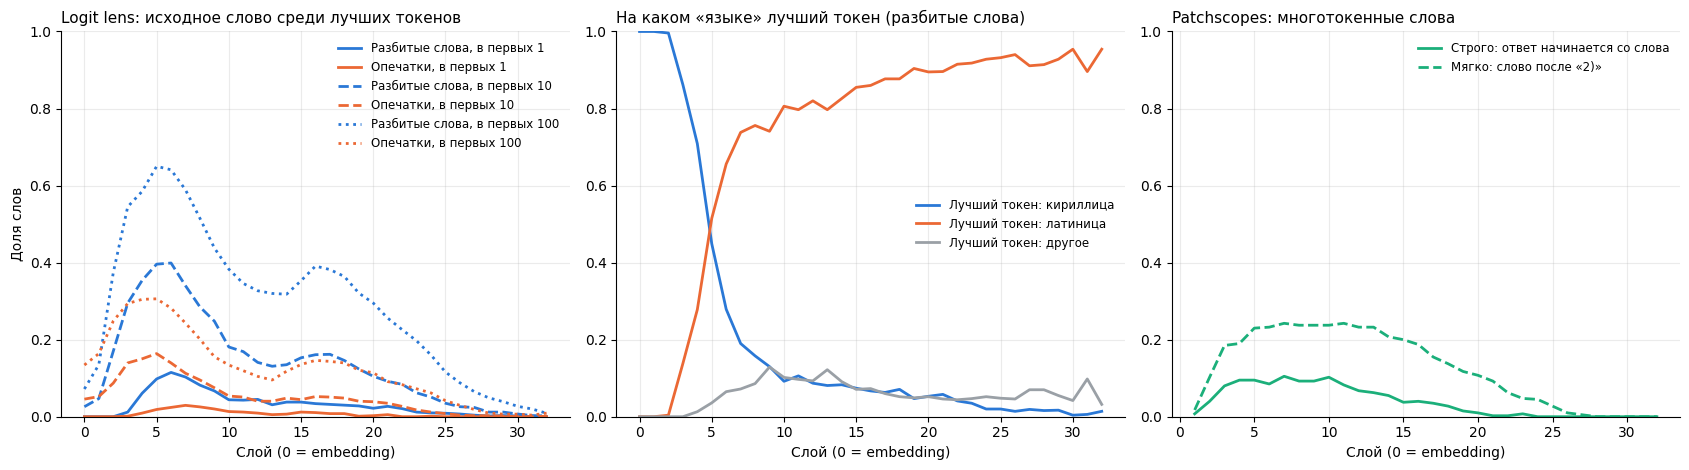

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
ax = axes[0]
for k, ls in [(1, "-"), (10, "--"), (100, ":")]:
    ax.plot(range(N_STATES), (split_rank < k).mean(1), color="#2a78d6", ls=ls, lw=2, label=f"Разбитые слова, в первых {k}")
    ax.plot(range(N_STATES), (typo_rank < k).mean(1), color="#eb6834", ls=ls, lw=2, label=f"Опечатки, в первых {k}")
ax.set_title("Logit lens: исходное слово среди лучших токенов", loc="left", fontsize=11)
ax.set_ylabel("Доля слов")
ax.set_ylim(0, 1)

ax = axes[1]
for col, color in [("кириллица", "#2a78d6"), ("латиница", "#eb6834"), ("другое", "#9aa0a6")]:
    if col in script_counts:
        ax.plot(script_counts.index, script_counts[col], color=color, lw=2, label=f"Лучший токен: {col}")
ax.set_title("На каком «языке» лучший токен (разбитые слова)", loc="left", fontsize=11)
ax.set_ylim(0, 1)

ax = axes[2]
ax.plot(by_layer.index, by_layer["strict"], color="#1baf7a", lw=2, label="Строго: ответ начинается со слова")
ax.plot(by_layer.index, by_layer["lenient"], color="#1baf7a", lw=2, ls="--", label="Мягко: слово после «2)»")
ax.set_title("Patchscopes: многотокенные слова", loc="left", fontsize=11)
ax.set_ylim(0, 1)

for ax in axes:
    ax.set_xlabel("Слой (0 = embedding)")
    ax.grid(alpha=0.25)
    ax.legend(frameon=False, fontsize=8.5)
fig.tight_layout()
fig.savefig(os.path.join(RESULT_DIR, "section4_rescored.png"), dpi=180, bbox_inches="tight")
plt.show()

## 11. Скачать результаты

In [ ]:
from google.colab import files
for name in ["section4_retrieval_by_layer.png", "summary.csv", "logit_lens_by_layer.csv",
             "patchscopes_by_layer.csv", "patchscopes_outputs.csv", "split_words.csv", "typo_words.csv"]:
    files.download(os.path.join(RESULT_DIR, name))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

...

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>